# Block 06: Prisanalys

I denna notebook undersöker vi om sentimentet skiljer sig mellan olika prissegment. Analysen är kompletterande och deskriptiv: den visar samband i datan men menas INTE, att priset orsakar sentimentet

Här nedan laddar vi in bibliotek och funktioner som behövs. Vi ser till att python hittar rätt inne i projektet och skapar en mapp där vi kan spara våra diagram

In [1]:
from pathlib import Path
import os
import sys

# Går upp till projektets rotmapp så att relativa sökvägar fungerar
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)


# Lägger  till rotmappen så att mappen scripts kan importeras
sys.path.insert(0, str(Path.cwd()))

from IPython.display import Image, display

# Hämtar färdiga funktioner från prisfilen
from scripts.price_segment_analysis import (
    OUTPUT_DIR,
    add_price_segment,
    average_rating,
    extreme_comparison,
    load_priced_reviews,
    plot_average_rating,
    plot_extremes,
    plot_share,
    sentiment_share,
)

# Skapar output mapp där diagrammen ska sparas
OUTPUT_DIR.mkdir(exist_ok=True)

## Koppla recensioner till pris

Vi kopplar ihop recensionerna med produktens metadata med hjälp av ett unikt ID (parent_asin). Kopplingen är många-till-en. Om det skulle finnas dubbletter i metadatan stoppas körningen direkt för att undvika fel.

Vi rensar bort alla produkter som saknar pris. Sedan delar vi upp de kvarvarande i tre lika grupper (tertiler): low (billig), mid (mellan) och high (dyr)

In [2]:
priced = add_price_segment(load_priced_reviews())

print("Recensioner med pris:", len(priced))

# Visar pris och antal recensioner per segment
priced.groupby("segment", observed=True)["price"].agg(["min", "max", "count"])

Recensioner med pris: 26229


,min,max,count
segment,,,
low,0.01,11.99,9539
mid,12.00,20.90,7948
high,20.93,2199.00,8742


## Sentiment per prissegment

Tabellen här under visar andelen i % negativa, neutrala och positiva recensioner inom varje prissegment. Vi väljer att titta på procent istället för exakta antal då positiva recensioner är så pass många fler i vår data totalt sett

sentiment,negative,neutral,positive
segment,,,
low,19.1,8.0,72.9
mid,17.1,7.1,75.7
high,16.0,6.3,77.8


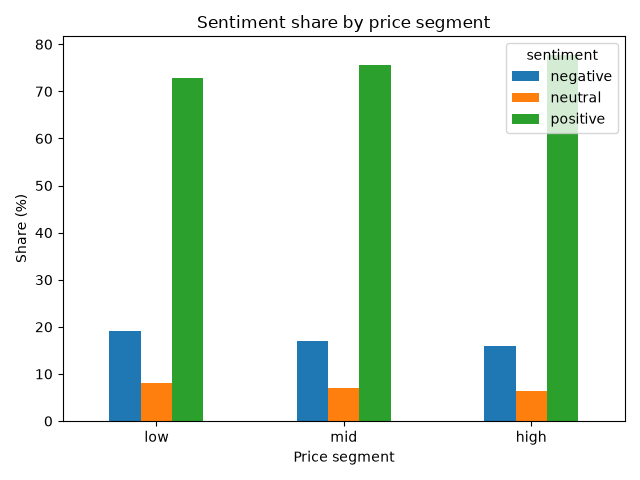

In [3]:
share = sentiment_share(priced)
display(share)

# visar fördelningen
plot_share(share)
display(Image(OUTPUT_DIR / "sentiment_by_price_segment.png"))

Andel positiva recensioner ökar med priset, från 72,9% till 77,8% (från låg till hög grupp). De negativa minskar från 19,1% till 16,0%. Skillnaderna är små: sentimentet är i alla segment övervägande positivt.

## Medelbetyg per prissegment

Som ett andra mått jämför vi medelbetyget (1-5 stjärnor) mellan segmenten. Betyget används här bara för beskrivning och är inte en feature i modellen

segment
low     4.04
mid     4.12
high    4.18
Name: rating, dtype: float64

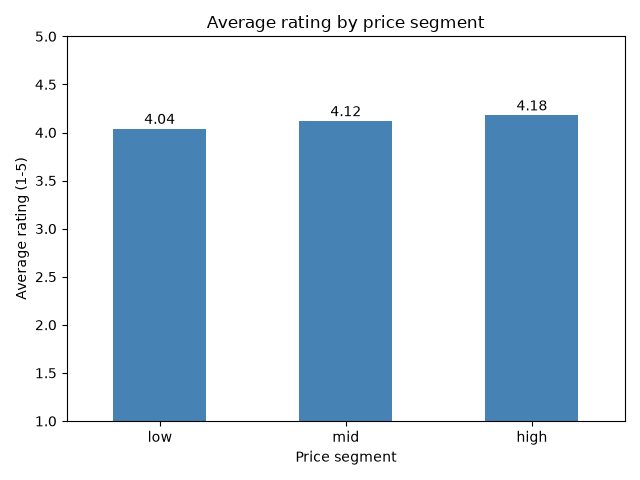

In [4]:
avg = average_rating(priced)
display(avg)

plot_average_rating(avg)
display(Image(OUTPUT_DIR / "average_rating_by_segment.png"))

Medelbetyget stiger svagt med priset: 4,04 (låg), 4,12 (mid) och 4,18 (hög). Det stämmer med mönstret i sentimentandelarna, men väldigt liten skillnad

# Billigaste mot dyraste 10%

Tertilerna kan dölja skillnader i ytterkanterna. Därför jämför vi också de billigaste/dyraste 10% av produkterna

sentiment,negative,neutral,positive
group,,,
cheapest 10%,21.5,9.5,69.0
priciest 10%,14.5,5.7,79.8


group
cheapest 10%    2712
priciest 10%    2636
Name: count, dtype: int64

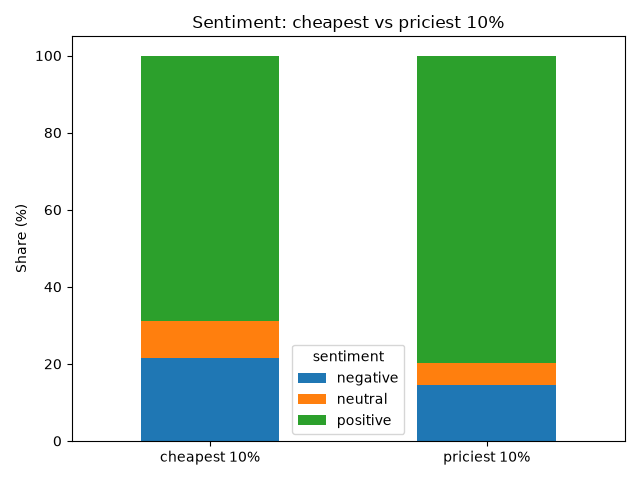

In [5]:
extremes_share, extremes_counts = extreme_comparison(priced)
display(extremes_share)
display(extremes_counts)

plot_extremes(extremes_share)
display(Image(OUTPUT_DIR / "sentiment_extremes.png"))

Skillnaden är något tydligare på ytterkanter:
- 69,0% positiva recensioner bland de billigaste 10% mot 79,8% bland de dyraste 10%
- Negativa recensioner är 21,5% mot 14,5%.
- Varje grupp har cirka 2600 recensioner, vilket fungerar för en deskriptiv jämförelse

## Sammanfattning av resultat och begränsningar

Våra viktigaste insikter och saker vi måste tänka på när vi tolkar prisanalysen:

- Ju dyrare prissegment en produkt tillhör, desto mer positiva är recensionerna. Andelen positiva omdömen klättrar från 72,9% för de billigaste produkterna upp till 77,8% för de dyraste. Det genomsnittliga stjärnbetyget följer precis samma mönster.
- När vi zoomar in på ytterkanterna och jämför de absolut billigaste och dyraste 10% av produkterna blir skillnaderna i kundupplevelser ännu mer tydliga än när vi bara tittar på de tre stora prissegmenten.
- Bara c.a 26% av recensioner hade ett pris, och priset är dessutom hämtat när datan samlades in och inte när recensionerna faktiskt skrevs. Eftersom andelen med pris skiljer sig mellan sentimenten är det urvalet inte slumpmässigt.
- Även om vi ser dessa samband kan vi inte bevisa att det är just priset som orsakar att kunderna blir nöjdare. Analysen är bara beskrivande, och skillnader kan lika gärna bero på produktkvalitet, förväntningar, produkttyp eller antal recensioner per produkt.